In [12]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


This notebook determines the range of fire areas in which the 3 fire area datasets are in agreement by minimizing the Kuiper statistic of their CDFs over the region where the datasets overlap spatially and temporally.

In [13]:
import numpy as np

from wildfire_stats import config as cfg
from wildfire_stats.data import io as dio
from wildfire_stats.plotting import dataset_comp as pdc
from wildfire_stats.reporting import summaries as rsum

P = cfg.load_paths()
A = cfg.load_assumptions()

SAVE_FIGS = True

### MTBS vs. GFD

In [14]:
mtbs_proj = dio.load_mtbs(P.mtbs / "S_USA.MTBS_BURN_AREA_BOUNDARY.shp",
                          area_col="area_km2")
idaho_gdf = dio.load_idaho(P.idaho / "HFD_HistoricFiresDatabase8_0.gdb")

# MTBS starts in 1984; GFA / MODIS cover modis_years
mtbs_proj = dio.filter_years(mtbs_proj, "YEAR", (1984, 2016))
idaho_gdf = dio.filter_years(idaho_gdf, "FIRE_YEAR", (1984, 2016))
idaho_gdf2 = dio.filter_years(idaho_gdf, "FIRE_YEAR", A["modis_years"])

mtbs_overlap = dio.overlap_with(mtbs_proj, idaho_gdf, dedup_col="FIRE_ID")

rsum.print_summary("MTBS", mtbs_overlap, "YEAR")
rsum.print_summary("Idaho", idaho_gdf, "FIRE_YEAR")

/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:198: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(



MTBS dataset:
  Number of fires: 8736
  Year range: 1984 - 2016
  Mean fire size: 38.23 km²
  Median fire size: 11.94 km²
  Min fire size: 4.05 km²
  Max fire size: 2296.22 km²
  Total burned area: 333992.45 km²

Idaho dataset:
  Number of fires: 33354
  Year range: 1984 - 2016
  Mean fire size: 11.03 km²
  Median fire size: 0.67 km²
  Min fire size: 0.00 km²
  Max fire size: 2462.94 km²
  Total burned area: 367836.11 km²


Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-cdf_vs_area_MTBS_vs_Idaho.png


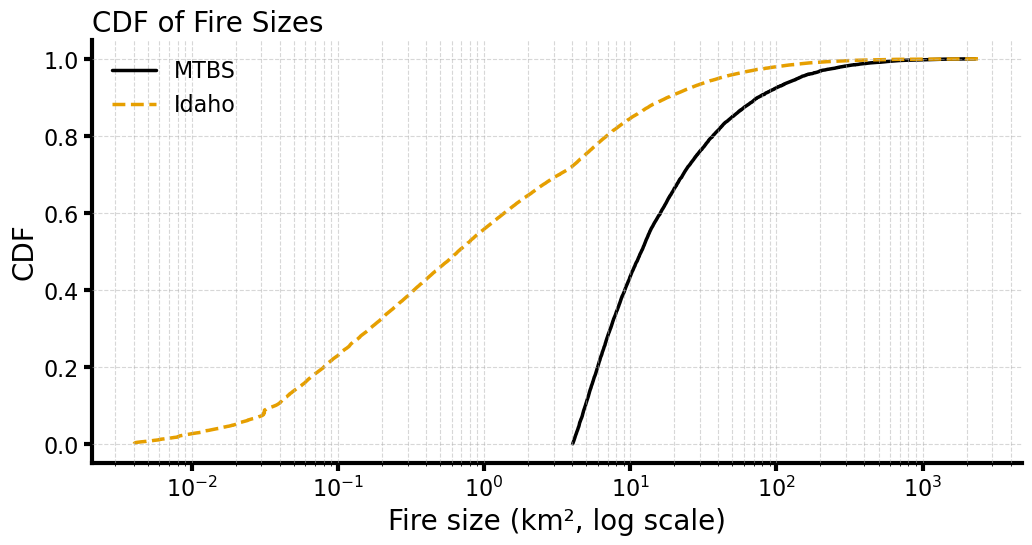

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-alpha_vs_kuiper_MTBS_vs_Idaho.png


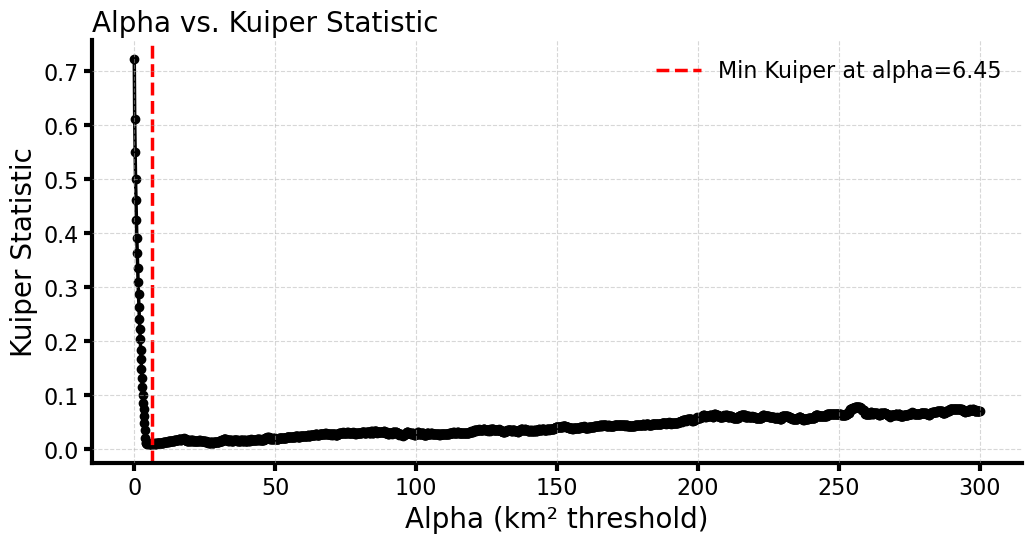

Minimum Kuiper statistic 0.0101 occurs at alpha = 6.4532 km²
Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-cdf_vs_area_min_kuiper_MTBS_vs_Idaho.png


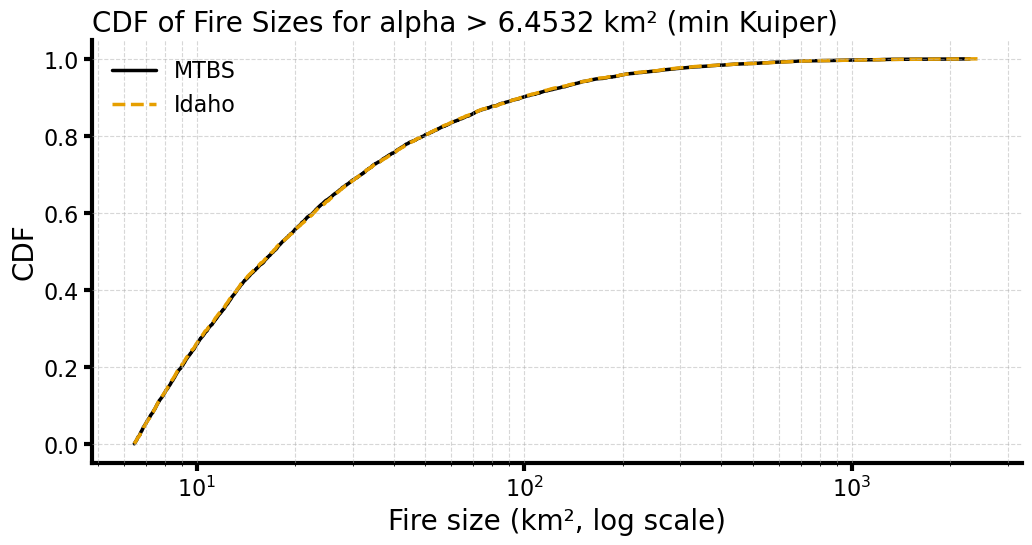

(np.float64(6.453226613306654), np.float64(0.010077897767335725))

In [15]:
alphas = np.linspace(0, 300, 2000)

pdc.plot_cdf_vs_area(mtbs_overlap, idaho_gdf, labels=("MTBS", "Idaho"),
                     save_figs=SAVE_FIGS)
pdc.plot_alpha_vs_kuiper_with_min_cdf(mtbs_overlap, idaho_gdf, 
                                      alphas, labels=("MTBS", "Idaho"),
                                      save_figs=SAVE_FIGS)

### GFA vs. GFD

In [16]:
gfa_combined_gdf = dio.load_gfa(P.gfa, verbose=True)

gfa_overlap = dio.overlap_with(gfa_combined_gdf, idaho_gdf2, dedup_col="geometry")

Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2003.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2004.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2005.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2006.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2007.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2008.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimete

/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2010.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2011.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2012.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2013.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2014.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2015.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2016.shp ...


/Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/.env/lib/python3.10/site-packages/pyogrio/raw.py:198: RuntimeWarning: /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2016.shp contains polygon(s) with rings with invalid winding order. Autocorrecting them, but that shapefile should be corrected using ogr2ogr for example.
  return ogr_read(


In [17]:
gfa_combined_gdf

,fire_ID,lat,lon,size,perimeter,start_date,start_DOY,end_date,end_DOY,duration,...,speed,direction,direction_s,landcover,landcover_s,tile_ID,geometry,area_km2,perim_km,YEAR
0,1,21.5312,-158.2120,6.43,12.04,2003-07-20,201,2003-07-30,211,11,...,0.91,8,northwest,12,Croplands,h03v06,"POLYGON ((-15267176.113 2685964.55, -15265447....",6.422292,13.527851,2003
1,2,20.6521,-156.2580,0.21,1.85,2003-06-27,178,2003-06-27,178,1,...,0.46,0,none,10,Grasslands,h03v06,"POLYGON ((-15077380.449 2579655.101, -15076950...",0.214056,2.153892,2003
2,3,20.6396,-156.2450,9.00,16.67,2003-07-08,189,2003-07-13,194,6,...,1.68,4,southeast,7,Open shrublands,h03v06,"POLYGON ((-15077842.875 2578658.635, -15077413...",8.990305,18.944715,2003
3,4,20.5396,-156.6680,1.50,7.41,2003-05-02,122,2003-05-11,131,10,...,0.86,4,southeast,7,Open shrublands,h03v06,"POLYGON ((-15116918.43 2566198.308, -15116489....",1.498333,8.607441,2003
4,5,19.4229,-155.4200,6.22,12.96,2003-02-25,56,2003-03-01,60,5,...,1.08,8,northwest,7,Open shrublands,h03v07,"POLYGON ((-14996775.822 2434119.064, -14996349...",6.206546,14.822210,2003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13250603,887214,-15.2729,145.1450,1.29,5.56,2016-10-10,284,2016-10-12,286,3,...,0.59,4,southeast,8,Woody savannas,h32v10,"POLYGON ((14004151.243 -1925763.587, 14004567....",1.283411,6.003259,2016
13250604,887218,-15.2771,145.1349,0.64,3.70,2016-11-17,322,2016-11-21,326,5,...,0.51,5,south,8,Woody savannas,h32v10,"POLYGON ((14002762.339 -1926276.845, 14003595....",0.641671,4.002177,2016
13250605,887219,-15.3104,145.1537,2.57,7.41,2016-10-21,295,2016-10-30,304,10,...,0.97,3,east,8,Woody savannas,h32v10,"POLYGON ((14003875.422 -1928329.78, 14004708.9...",2.566365,8.340486,2016
13250606,887220,-15.3021,145.1781,1.50,5.56,2016-10-02,276,2016-10-08,282,7,...,0.75,8,northwest,8,Woody savannas,h32v10,"POLYGON ((14007071.437 -1928842.989, 14007905....",1.497197,6.004779,2016


In [18]:
rsum.print_summary("GFA (overlap)", gfa_overlap, "YEAR")
rsum.print_summary("Idaho", idaho_gdf2, "FIRE_YEAR")


GFA (overlap) dataset:
  Number of fires: 9399
  Year range: 2003 - 2016
  Mean fire size: 15.98 km²
  Median fire size: 2.36 km²
  Min fire size: 0.21 km²
  Max fire size: 1970.34 km²
  Total burned area: 150164.50 km²

Idaho dataset:
  Number of fires: 16134
  Year range: 2003 - 2016
  Mean fire size: 12.46 km²
  Median fire size: 0.53 km²
  Min fire size: 0.00 km²
  Max fire size: 2462.94 km²
  Total burned area: 201013.49 km²


Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-cdf_vs_area_GFA_vs_Idaho.png


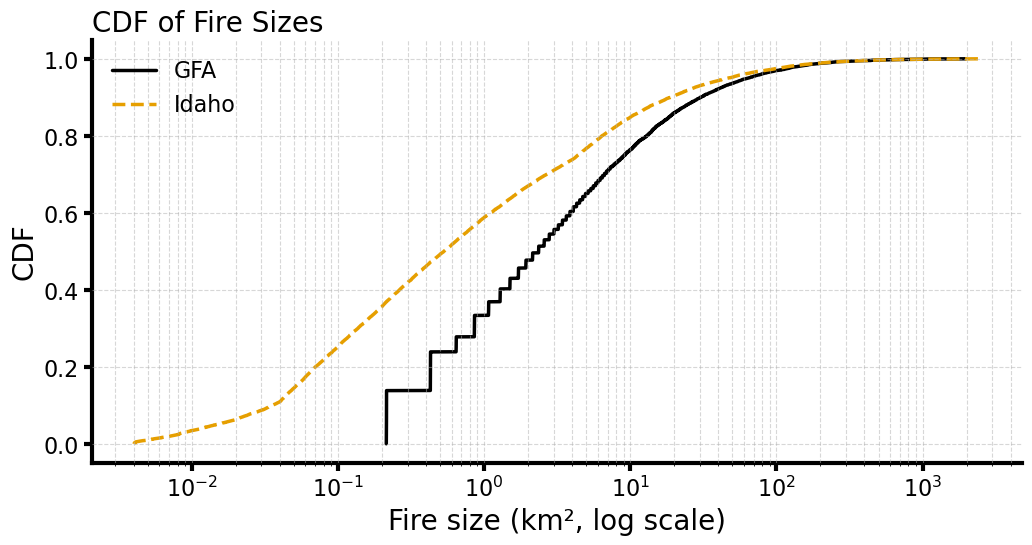

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-alpha_vs_kuiper_GFA_vs_Idaho.png


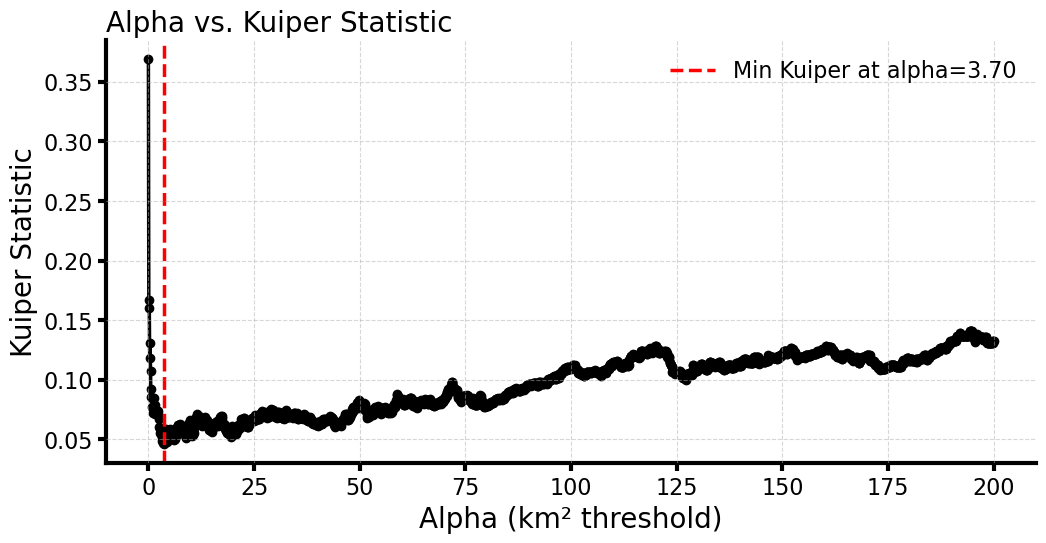

Minimum Kuiper statistic 0.0461 occurs at alpha = 3.7019 km²
Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-cdf_vs_area_min_kuiper_GFA_vs_Idaho.png


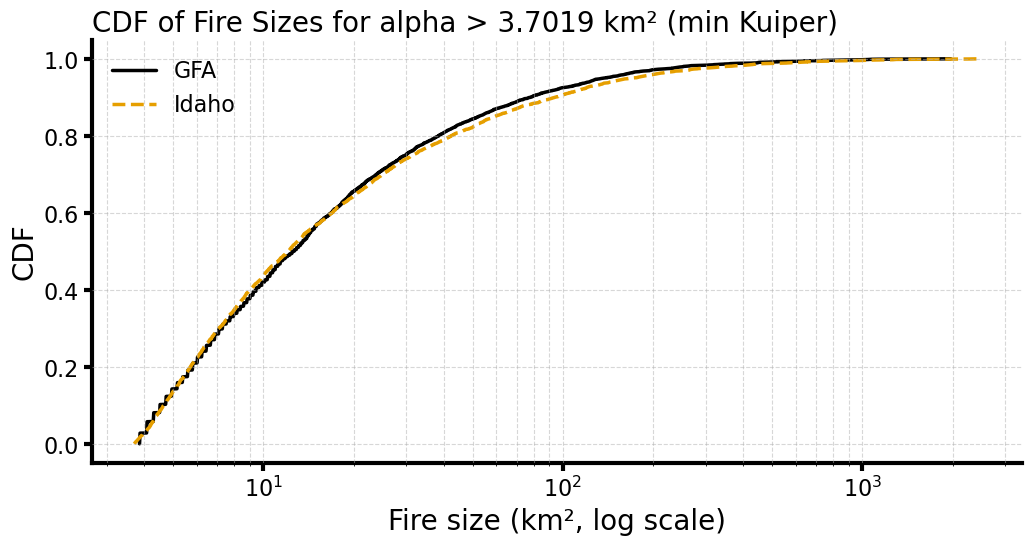

(np.float64(3.701850925462731), np.float64(0.046087608086439136))

In [19]:
alphas2 = np.linspace(0, 200, 2000)

pdc.plot_cdf_vs_area(gfa_overlap, idaho_gdf2, labels=("GFA", "Idaho"),
                     save_figs=SAVE_FIGS)
pdc.plot_alpha_vs_kuiper_with_min_cdf(gfa_overlap, idaho_gdf2, alphas2, 
                                      labels=("GFA", "Idaho"),
                                      save_figs=SAVE_FIGS)

### GFA vs. MTBS

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-cdf_vs_area_GFA_vs_MTBS.png


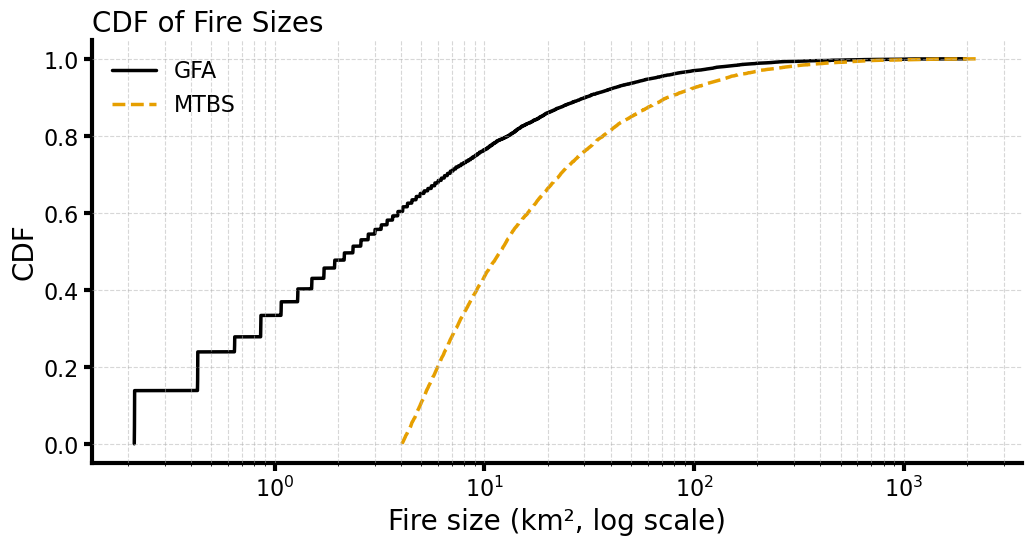

Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-alpha_vs_kuiper_GFA_vs_MTBS.png


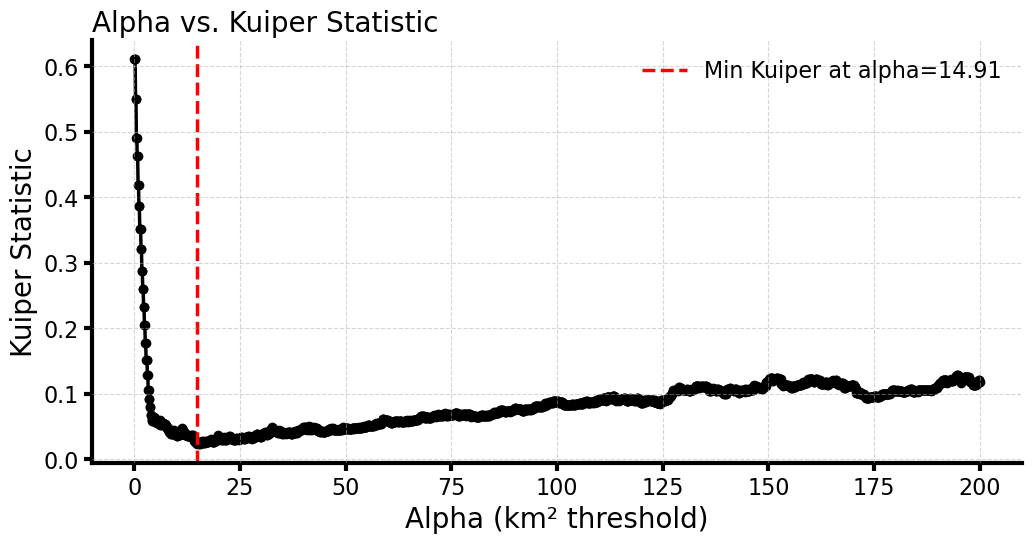

Minimum Kuiper statistic 0.0232 occurs at alpha = 14.9075 km²
Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-cdf_vs_area_min_kuiper_GFA_vs_MTBS.png


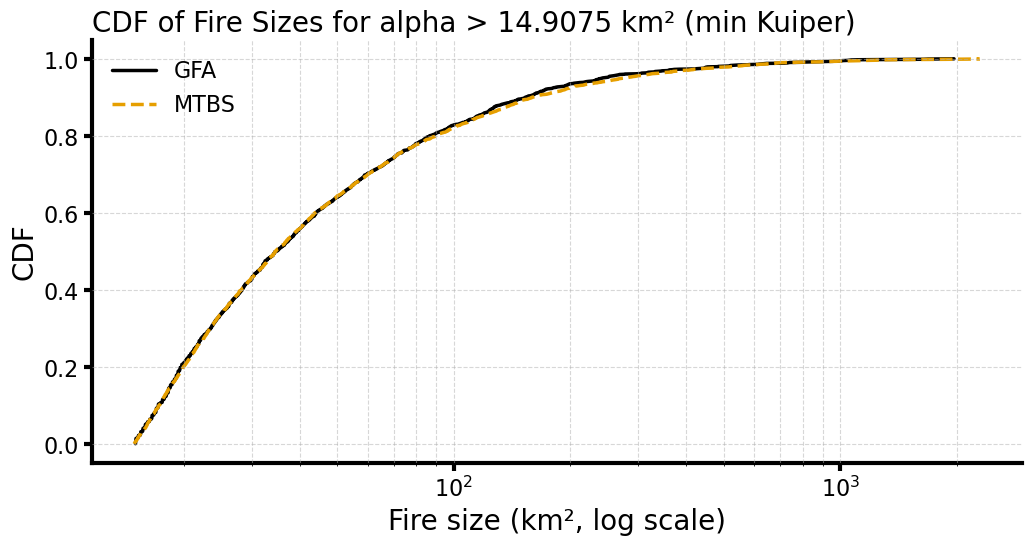

(np.float64(14.90745372686343), np.float64(0.023167234052925367))

In [20]:
pdc.plot_cdf_vs_area(gfa_overlap, mtbs_overlap, labels=("GFA", "MTBS"),
                     save_figs=SAVE_FIGS)
pdc.plot_alpha_vs_kuiper_with_min_cdf(gfa_overlap, mtbs_overlap, alphas2, 
                                      labels=("GFA", "MTBS"),
                                      save_figs=SAVE_FIGS)

Based on the minimum fire size cutoffs that minimize the Kuiper statistic, all future notebooks will remove fires less than 4 km^2.